In [20]:
import torch
import torch.nn as nn
import pickle
import json
from torch.utils.data import DataLoader

from src.classifier import Classifier
from src.trainer import Trainer
from src.datasets_classes import MultiDomainDataset, multidomain_collate_fn
from src.config import NATIVE_MODEL_BY_DOMAIN
from src.utils.evaluation import compute_classification_reports, save_confusion_matrices, build_summary_table, plot_domain_metric_bar, save_combined_confusion_matrix

In [22]:
with open("outputs/models/fitted_pcas_w2v.pkl", "rb") as f:
    fitted_pcas = pickle.load(f)

In [23]:
test_dataset = MultiDomainDataset("outputs/embeddings/utterance/test", native_only=True, w2v=True)

In [24]:
for domain_name in test_dataset.domain_data:
    test_embeddings = test_dataset.domain_data[domain_name]["embedding"]
    if isinstance(test_embeddings, torch.Tensor):
        test_embeddings = test_embeddings.numpy()

    test_reduced = fitted_pcas[domain_name].transform(test_embeddings)
    test_dataset.domain_data[domain_name]["embedding"] = torch.tensor(test_reduced, dtype=torch.float32)

In [25]:
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, collate_fn=multidomain_collate_fn)

In [26]:
native_model = NATIVE_MODEL_BY_DOMAIN
native_model["soundscapes"] = "wav2vec"

In [27]:
checkpoint = torch.load("outputs/models/best_model_w2v.pt", map_location=torch.device("cpu"))


projectors = nn.ModuleDict({domain: nn.Identity() for domain in native_model})
classifier = Classifier(shared_dim=checkpoint["shared_dim"], hidden_dim = checkpoint["hidden_dim"], dropout=checkpoint["dropout"])

projectors.load_state_dict(checkpoint["projectors_state_dict"])
classifier.load_state_dict(checkpoint["classifier_state_dict"])

trainer = Trainer(projectors, classifier, shared_dim=checkpoint["shared_dim"])

In [28]:
import pandas as pd
from IPython.display import display

def display_classification_reports(reports):
    for split_name, split_data in reports.items():
        print(f"\n {split_name} - overall")
        overall_df = pd.DataFrame(split_data["overall"]).transpose()
        display(overall_df)

        for domain, domain_report in split_data["domains"].items():
            print(f"\n {split_name} - {domain}")
            domain_df = pd.DataFrame(domain_report).transpose()
            display(domain_df)

In [29]:
print(list(trainer.projectors.keys()))
print(set(d for _, _, doms in test_loader for d in doms))

['speech', 'music', 'animal', 'soundscapes']
{'animal', 'music', 'soundscapes', 'speech'}


In [31]:
splits = [("test", test_loader)]
reports = compute_classification_reports(trainer, splits)
display_classification_reports(reports)

with open("outputs/tables/test_classification_report_w2v.json", "w") as f:
    json.dump(reports, f, indent=2)


 test - overall


,precision,recall,f1-score,support
0,0.946254,0.931587,0.938863,1871.000000
1,0.792545,0.831633,0.811618,588.000000
accuracy,0.907686,0.907686,0.907686,0.907686
macro avg,0.869399,0.881610,0.875241,2459.000000
weighted avg,0.909499,0.907686,0.908436,2459.000000
balanced_accuracy,0.881610,0.881610,0.881610,0.881610



 test - animal


,precision,recall,f1-score,support
0,0.882591,0.908333,0.895277,240.000000
1,0.614035,0.546875,0.578512,64.000000
accuracy,0.832237,0.832237,0.832237,0.832237
macro avg,0.748313,0.727604,0.736895,304.000000
weighted avg,0.826053,0.832237,0.828590,304.000000
balanced_accuracy,0.727604,0.727604,0.727604,0.727604



 test - music


,precision,recall,f1-score,support
0,0.500000,0.761905,0.603774,21.000000
1,0.888889,0.714286,0.792079,56.000000
accuracy,0.727273,0.727273,0.727273,0.727273
macro avg,0.694444,0.738095,0.697926,77.000000
weighted avg,0.782828,0.727273,0.740723,77.000000
balanced_accuracy,0.738095,0.738095,0.738095,0.738095



 test - soundscapes


,precision,recall,f1-score,support
0,0.672727,0.606557,0.637931,61.000000
1,0.641791,0.704918,0.671875,61.000000
accuracy,0.655738,0.655738,0.655738,0.655738
macro avg,0.657259,0.655738,0.654903,122.000000
weighted avg,0.657259,0.655738,0.654903,122.000000
balanced_accuracy,0.655738,0.655738,0.655738,0.655738



 test - speech


,precision,recall,f1-score,support
0,0.976127,0.950291,0.963036,1549.000000
1,0.828125,0.911548,0.867836,407.000000
accuracy,0.942229,0.942229,0.942229,0.942229
macro avg,0.902126,0.930919,0.915436,1956.000000
weighted avg,0.945331,0.942229,0.943227,1956.000000
balanced_accuracy,0.930919,0.930919,0.930919,0.930919


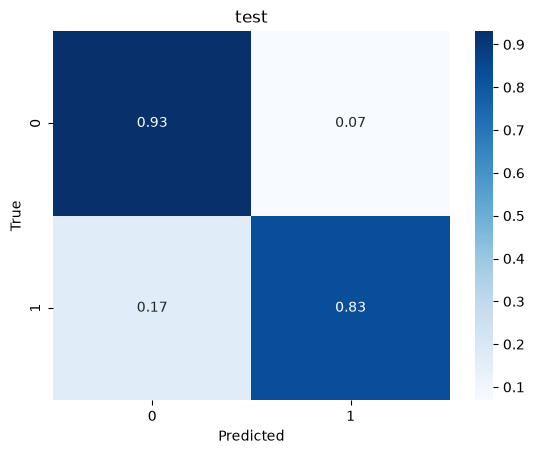

In [32]:
save_confusion_matrices(trainer, splits, output_dir="plots/confusion_matrices/w2v")

In [33]:
summary_df = build_summary_table(reports, split_name="test")
display(summary_df)

,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
domain,,,,,
animal,0.832237,0.727604,0.748313,0.727604,0.736895
music,0.727273,0.738095,0.694444,0.738095,0.697926
soundscapes,0.655738,0.655738,0.657259,0.655738,0.654903
speech,0.942229,0.930919,0.902126,0.930919,0.915436


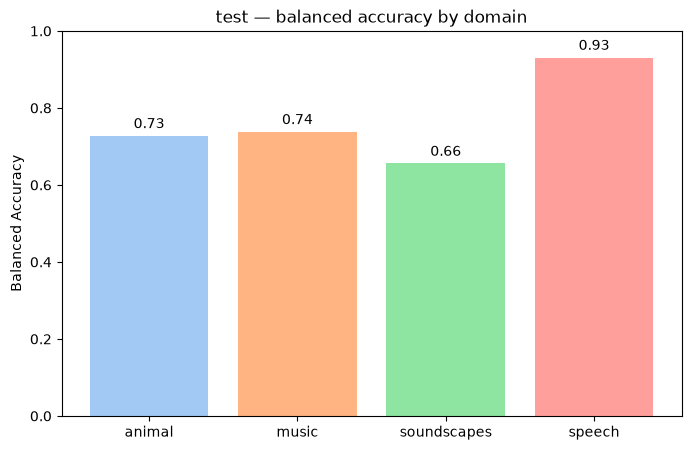

In [35]:
plot_domain_metric_bar(reports, split_name="test", metric="balanced_accuracy", filename="plots/utterance/domain_summary_bar_w2v.png")

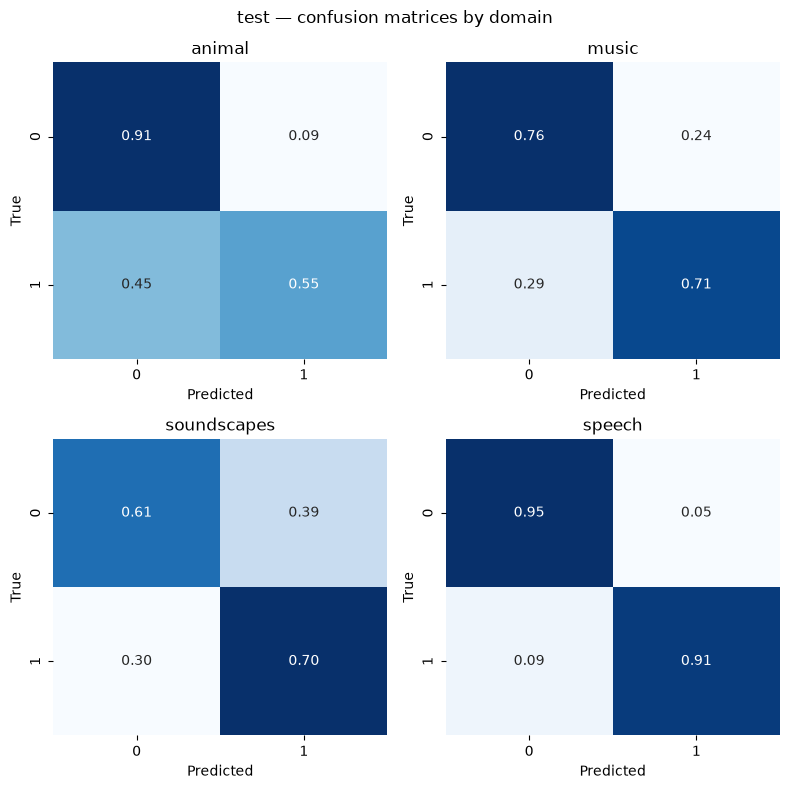

In [36]:
save_combined_confusion_matrix(trainer, test_loader, split_name="test", output_dir="plots/confusion_matrices/w2v")